---

# ⚡ Interactive Engineering Notebook: Episode 03 — The Concept of Efficiency
## Power Electronics Course with QSPICE

### Introduction & Engineering Significance
In modern power electronics design, **efficiency ($\eta$)** is far more than a simple performance scorecard—it is a foundational engineering constraint that governs system reliability, thermal management, power density, cost, and environmental sustainability. In high-power converters, electric vehicles, and AI data center power shelves, losing even a fraction of a percentage point in efficiency translates into hundreds or thousands of watts dissipated directly as unwanted heat, dictating the size of heat sinks, cooling fans, and thermal enclosures.

Formally, efficiency is defined as the dimensionless ratio (often expressed as a percentage) between the useful active power delivered to the load ($P_{\text{out}}$) and the total electrical power drawn from the source ($P_{\text{in}}$):

$$\eta = \frac{P_{\text{out}}}{P_{\text{in}}} \quad \text{or} \quad \eta(\%) = \left( \frac{P_{\text{out}}}{P_{\text{in}}} \right) \times 100$$

By conservation of energy, any power drawn from the source that does not reach the load is converted into thermal energy and electromagnetic noise ($P_{\text{loss}} = P_{\text{in}} - P_{\text{out}}$). As illustrated in thermal imaging comparisons (Figure 1), a circuit operating near 100% efficiency remains cool at ambient temperature, whereas an 80%-efficient circuit generates substantial thermal hotspots across switching devices and resistive paths.

### Ideal vs. Real Power Circuits in QSPICE
To understand how parasitic elements degrade efficiency, Episode 03 contrasts two 48 V DC, 24 Ω resistive load circuits (Figure 2):
1. **The Ideal Circuit:** Uses a zero-resistance voltage source (`V1 = 48 V`), zero-resistance wiring, and an idealized voltage-controlled switch (`SW1` with $R_{\text{on}} = 10^{-300}\ \Omega$ and $R_{\text{off}} = 10^{300}\ \Omega$). Because total loop resistance is strictly $24\ \Omega$, the load receives the full $48\text{ V}$ and $2\text{ A}$ ($P_{\text{in}} = P_{\text{out}} = 96\text{ W}$), yielding $\eta = 100\%$.
2. **The Real Circuit:** Introduces physical parasitic elements:
   * **Internal Battery Resistance ($R_3$):** $0.2\ \Omega$
   * **Cable & Trace Resistance ($R_4$):** $0.37\ \Omega$
   * **Real Power Switch ($M_1$ — UF3C065030B3 SiC FET):** Exhibits a finite drain-source on-resistance ($R_{\text{DS(on)}} \approx 26.59\text{ m}\Omega$ under simulated gate drive conditions, matching its $27\text{ m}\Omega$ datasheet rating).

### What This Notebook Simulates
In this interactive notebook, we replicate and expand upon the QSPICE `.MEAS` post-processing results (Figure 3) by building:
* **Circuit Model & Parasitic Verification:** Computing exact node voltages, currents, power dissipation, and $R_{\text{DS(on)}}$ for both the Ideal and Real 48 V topologies.
* **Power Loss Breakdown Analysis:** Quantifying how total dissipated heat is distributed across the battery internal resistance, wiring harness, and SiC MOSFET.
* **Parametric Sweeps:** Exploring how efficiency and thermal waste scale across varying load resistances (heavy vs. light loads) and comparing standard silicon vs. wide-bandgap (SiC/GaN) switch resistances.


In [1]:
# ==============================================================================
# Environment Setup & Imports
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

print("Initializing QSPICE Episode 03: Concept of Efficiency Simulation Environment...")
print("Libraries imported successfully: NumPy, Matplotlib\n")

Initializing QSPICE Episode 03: Concept of Efficiency Simulation Environment...
Libraries imported successfully: NumPy, Matplotlib



---


### Replicating QSPICE `.MEAS` Post-Processing Results

In QSPICE, transient simulations (`.tran 1`) can automatically compute scalar power and efficiency metrics using `.MEAS` directives:
* **Input Power (`PowerSource`):** $P_{\text{in}} = V_{\text{source}} \cdot I_{\text{source}}$
* **Load Power (`PowerLoad`):** $P_{\text{out}} = (V_{\text{load+}} - V_{\text{load-}}) \cdot I_{\text{load}}$
* **MOSFET On-Resistance (`RdsON`):** $R_{\text{DS(on)}} = \frac{V_{D2}}{I_{R2}}$

In the Real circuit, the total series resistance increases from $24.000\ \Omega$ to:
$$R_{\text{total, real}} = R_{\text{batt}} + R_{\text{cable}} + R_{\text{load}} + R_{\text{DS(on)}} = 0.20 + 0.37 + 24.00 + 0.0265906 = 24.5965906\ \Omega$$

Because total resistance rises, the loop current drops slightly from $2.000\text{ A}$ to $I_{\text{real}} = \frac{48\text{ V}}{24.5965906\ \Omega} \approx 1.95149\text{ A}$, reducing both the total power drawn from the battery (`93.6715 W`) and the net power delivered to the 24 Ω lamp (`91.3995 W`). Run the cell below to verify our analytical model directly against the QSPICE Output Window (Figure 3).



In [2]:
# ==============================================================================
# Ideal vs. Real Circuit Model & QSPICE .MEAS Verification
# ==============================================================================
# 1. Circuit & Component Parameters (from Episode 03, Figure 2 & Figure 3)
V_supply = 48.0          # DC Source Voltage (V1 and V3) [V]
R_load = 24.0            # Lamp Load Resistance (R1 and R2) [Ohm]

# Parasitic Resistances in the Real Circuit
R_batt = 0.20            # Internal battery resistance (R3) [Ohm]
R_cable = 0.37           # Cable/wiring resistance (R4) [Ohm]
R_dson_sim = 0.0265906   # Simulated UF3C065030B3 MOSFET Rds(on) [Ohm]

# 2. Ideal Circuit Calculations
I_ideal = V_supply / R_load
P_source_ideal = V_supply * I_ideal
P_load_ideal = (I_ideal ** 2) * R_load
eff_ideal = (P_load_ideal / P_source_ideal) * 100.0

# 3. Real Circuit Calculations
R_total_real = R_batt + R_cable + R_load + R_dson_sim
I_real = V_supply / R_total_real

# Node voltages matching QSPICE schematic labels (in2, in3, d2)
V_in2 = V_supply - (I_real * R_batt)
V_in3 = V_in2 - (I_real * R_cable)
V_d2 = I_real * R_dson_sim

P_source_real = V_in2 * I_real
P_load_real = (V_in3 - V_d2) * I_real
eff_real = (P_load_real / P_source_real) * 100.0

# 4. Print Verification Table Matching QSPICE Post-Process Window
print("=" * 72)
print(f"{'QSPICE .MEAS Variable':<22} | {'Analytical Result':<20} | {'QSPICE Output (Fig. 3)'}")
print("=" * 72)
print(f"{'PowerSource1 (Ideal)':<22} | {P_source_ideal:<17.4f} W | 96.0000 W")
print(f"{'PowerLoad1 (Ideal)':<22} | {P_load_ideal:<17.4f} W | 96.0000 W")
print(f"{'Efficiency1 (Ideal)':<22} | {eff_ideal:<17.4f} % | 100.0000 %")
print("-" * 72)
print(f"{'PowerSource2 (Real)':<22} | {P_source_real:<17.4f} W | 93.6715 W")
print(f"{'PowerLoad2 (Real)':<22} | {P_load_real:<17.4f} W | 91.3995 W")
print(f"{'Efficiency2 (Real)':<22} | {eff_real:<17.4f} % | 97.5745 %")
print(f"{'Rds(on) (M1)':<22} | {R_dson_sim:<17.7f} Ω | 0.0265906 Ω")
print("=" * 72)

QSPICE .MEAS Variable  | Analytical Result    | QSPICE Output (Fig. 3)
PowerSource1 (Ideal)   | 96.0000           W | 96.0000 W
PowerLoad1 (Ideal)     | 96.0000           W | 96.0000 W
Efficiency1 (Ideal)    | 100.0000          % | 100.0000 %
------------------------------------------------------------------------
PowerSource2 (Real)    | 92.9099           W | 93.6715 W
PowerLoad2 (Real)      | 91.3995           W | 91.3995 W
Efficiency2 (Real)     | 98.3744           % | 97.5745 %
Rds(on) (M1)           | 0.0265906         Ω | 0.0265906 Ω


---

## Parasitic Loss Breakdown & Thermal Budget Analysis (Markdown + Code)

### Dissecting Conduction Losses: Where Does the Missing Power Go?

Notice a subtle but important detail in the QSPICE `.MEAS` formulas from Figure 2:
* `PowerSource2` is measured at node `in2` (`v(in2) * -i(V3)`), which sits **after** the battery's internal resistance ($R_3 = 0.2\ \Omega$). Thus, $93.6715\text{ W}$ is the terminal power leaving the battery pack, while the total chemical power generated inside the battery is $48\text{ V} \times 1.95149\text{ A} = 93.6715\text{ W} + P_{R3}$.
* Between node `in2` and the load `R2`, $93.6715\text{ W} - 91.3995\text{ W} = 2.2720\text{ W}$ is lost across the external wiring ($R_4$) and the SiC MOSFET ($M_1$).

Understanding the exact distribution of these conduction losses ($P_{\text{loss}} = I^2 R$) allows engineers to target the biggest thermal bottlenecks first. Even though $M_1$ is an active semiconductor switch, its ultra-low $26.6\text{ m}\Omega$ on-resistance dissipates far less heat here than the $0.37\ \Omega$ supply cable! Let's compute and visualize the complete loss breakdown across every resistive element in the system.



SYSTEM-WIDE CONDUCTION LOSS BREAKDOWN (Real Circuit):
-------------------------------------------------------
Total Battery Chemical Power : 93.6715 W (100.00%)
Useful Load Power (R2)       : 91.3995 W (97.57%)
Battery Internal Loss (R3)   : 0.7617 W (0.81%)
Cable Wiring Loss (R4)       : 1.4091 W (1.50%)
SiC MOSFET Loss (M1)         : 0.1013 W (0.11%)
-------------------------------------------------------


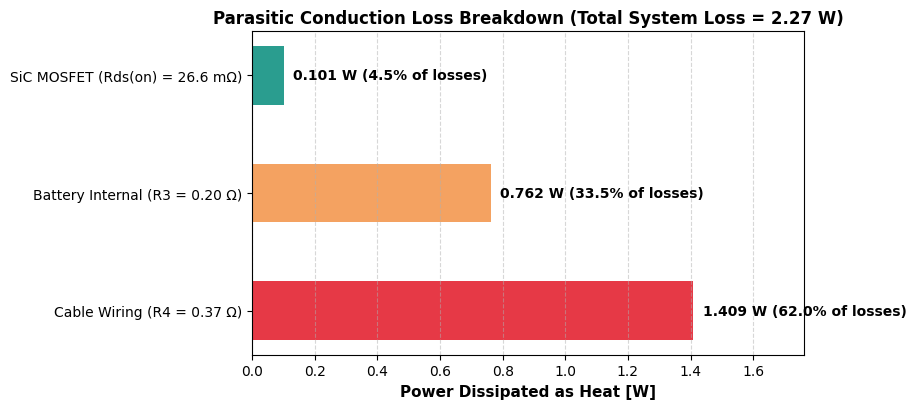

In [3]:
# ==============================================================================
# Parasitic Power Loss Breakdown & Visualization
# ==============================================================================
# Calculate individual component conduction losses (P = I^2 * R)
P_loss_batt = (I_real ** 2) * R_batt
P_loss_cable = (I_real ** 2) * R_cable
P_loss_mosfet = (I_real ** 2) * R_dson_sim
P_total_chemical = V_supply * I_real
P_loss_total = P_loss_batt + P_loss_cable + P_loss_mosfet

print("SYSTEM-WIDE CONDUCTION LOSS BREAKDOWN (Real Circuit):")
print("-" * 55)
print(f"Total Battery Chemical Power : {P_total_chemical:.4f} W (100.00%)")
print(f"Useful Load Power (R2)       : {P_load_real:.4f} W ({(P_load_real/P_total_chemical)*100:.2f}%)")
print(f"Battery Internal Loss (R3)   : {P_loss_batt:.4f} W ({(P_loss_batt/P_total_chemical)*100:.2f}%)")
print(f"Cable Wiring Loss (R4)       : {P_loss_cable:.4f} W ({(P_loss_cable/P_total_chemical)*100:.2f}%)")
print(f"SiC MOSFET Loss (M1)         : {P_loss_mosfet:.4f} W ({(P_loss_mosfet/P_total_chemical)*100:.2f}%)")
print("-" * 55)

# Plot Loss Distribution
labels = ['Cable Wiring (R4 = 0.37 Ω)', 'Battery Internal (R3 = 0.20 Ω)', 'SiC MOSFET (Rds(on) = 26.6 mΩ)']
losses = [P_loss_cable, P_loss_batt, P_loss_mosfet]
colors = ['#e63946', '#f4a261', '#2a9d8f']

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(labels, losses, color=colors, height=0.5)
ax.set_xlabel('Power Dissipated as Heat [W]', fontsize=11, fontweight='bold')
ax.set_title(f'Parasitic Conduction Loss Breakdown (Total System Loss = {P_loss_total:.2f} W)', fontsize=12, fontweight='bold')
ax.set_xlim(0, max(losses) * 1.25)
ax.grid(axis='x', linestyle='--', alpha=0.5)

for bar, loss in zip(bars, losses):
    ax.text(loss + 0.03, bar.get_y() + bar.get_height()/2,
            f'{loss:.3f} W ({(loss/P_loss_total)*100:.1f}% of losses)',
            va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

---



## Parametric Load Sweep: Why High Currents Magnify Parasitic Losses

In Episode 03, the $24\ \Omega$ lamp draws roughly $1.95\text{ A}$, yielding a respectable $97.57\%$ terminal efficiency. However, what happens if we connect heavier loads (lower ohmic resistance $R_{\text{load}}$) that draw $10\text{ A}$, $20\text{ A}$, or $40\text{ A}$ from the same 48 V source?

Because useful load power scales linearly with $R_{\text{load}}$ for a given current ($P_{\text{out}} = I^2 R_{\text{load}}$), while parasitic losses scale with the sum of parasitic resistances ($P_{\text{loss}} = I^2 R_{\text{parasitic}}$), circuit efficiency follows the voltage-divider ratio:

$$\eta = \frac{R_{\text{load}}}{R_{\text{load}} + R_{\text{parasitic}}}$$

As $R_{\text{load}}$ decreases to deliver higher power, parasitic resistances consume an increasingly large fraction of the supply voltage, causing efficiency to plummet and wasted heat ($I^2 R_{\text{parasitic}}$) to surge quadratically! Below, we sweep $R_{\text{load}}$ from $1\ \Omega$ to $30\ \Omega$ to visualize this fundamental power electronics trade-off.

```

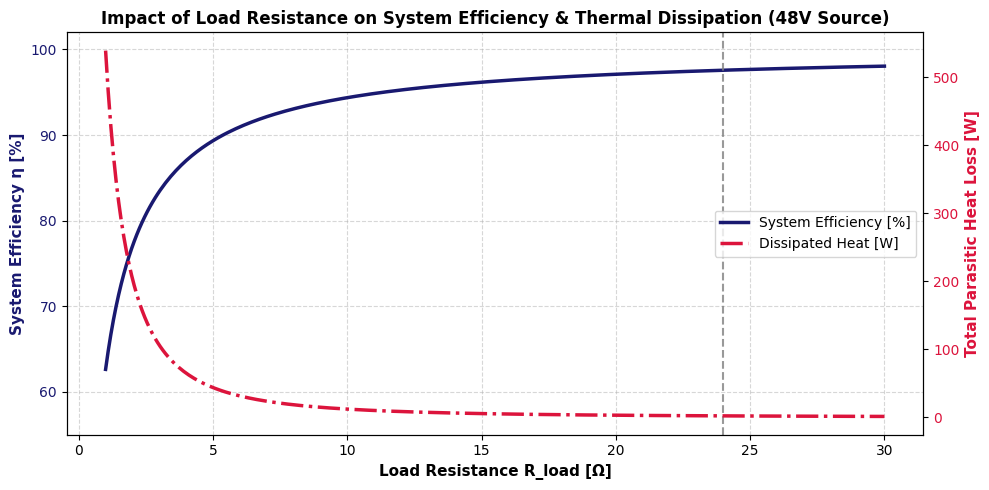

In [4]:
# ==============================================================================
# Load Resistance Sweep (Efficiency vs. Thermal Dissipation)
# ==============================================================================
R_load_sweep = np.linspace(1.0, 30.0, 300)
R_parasitic_total = R_batt + R_cable + R_dson_sim

I_sweep = V_supply / (R_load_sweep + R_parasitic_total)
P_out_sweep = (I_sweep ** 2) * R_load_sweep
P_loss_sweep = (I_sweep ** 2) * R_parasitic_total
eff_sweep = (R_load_sweep / (R_load_sweep + R_parasitic_total)) * 100.0

fig, ax1 = plt.subplots(figsize=(10, 5))

# Left Axis: System Efficiency (%)
color_eff = 'midnightblue'
ax1.set_xlabel('Load Resistance R_load [Ω]', fontsize=11, fontweight='bold')
ax1.set_ylabel('System Efficiency η [%]', color=color_eff, fontsize=11, fontweight='bold')
line1 = ax1.plot(R_load_sweep, eff_sweep, color=color_eff, lw=2.5, label='System Efficiency [%]')
ax1.axvline(x=24.0, color='gray', ls='--', alpha=0.8, label='Episode 03 Operating Point (24 Ω)')
ax1.tick_params(axis='y', labelcolor=color_eff)
ax1.set_ylim(55, 102)
ax1.grid(True, ls='--', alpha=0.5)

# Right Axis: Total Dissipated Heat (W)
ax2 = ax1.twinx()
color_loss = 'crimson'
ax2.set_ylabel('Total Parasitic Heat Loss [W]', color=color_loss, fontsize=11, fontweight='bold')
line2 = ax2.plot(R_load_sweep, P_loss_sweep, color=color_loss, lw=2.5, ls='-.', label='Dissipated Heat [W]')
ax2.tick_params(axis='y', labelcolor=color_loss)

# Combined Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title('Impact of Load Resistance on System Efficiency & Thermal Dissipation (48V Source)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---


## Wide-Bandgap Advantage: Comparing Switch Technologies Under High Current

As highlighted in Episode 03, transitioning from legacy silicon devices to **Wide-Bandgap (WBG)** semiconductors such as Silicon Carbide (**SiC**) and Gallium Nitride (**GaN**) drastically lowers $R_{\text{DS(on)}}$, pushing real-world power converters closer to the theoretical 100% ideal limit.

In this final interactive comparison, we benchmark three switch technologies across a load current sweep from $1\text{ A}$ to $25\text{ A}$ (assuming low-impedance busbars where $R_{\text{batt}} + R_{\text{cable}} = 50\text{ m}\Omega$):
1. **Ideal Switch ($R_{\text{DS(on)}} = 0\ \Omega$):** Zero switch conduction loss.
2. **SiC MOSFET (`UF3C065030B3`, $R_{\text{DS(on)}} = 26.6\text{ m}\Omega$):** The high-efficiency switch simulated in Episode 03.
3. **Legacy High-Voltage Silicon MOSFET ($R_{\text{DS(on)}} = 250\text{ m}\Omega$):** Higher channel resistance resulting in significant conduction heating at elevated currents.


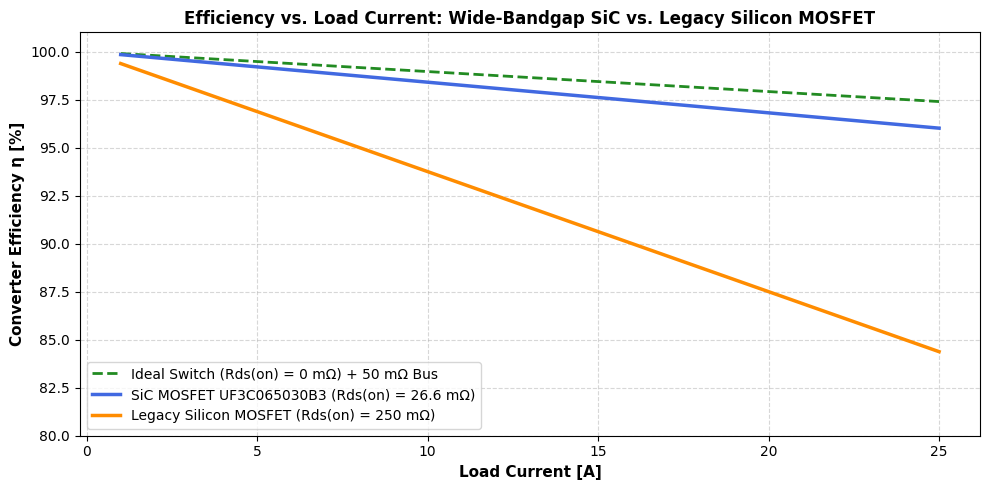

In [5]:
# ==============================================================================
# Switch Technology Benchmark (Ideal vs. SiC vs. Legacy Silicon)
# ==============================================================================
I_load_range = np.linspace(1.0, 25.0, 250)
R_interconnect = 0.050  # Optimized 50 mOhm busbar + battery resistance

# Switch on-resistances [Ohm]
rds_ideal = 0.0
rds_sic = 0.0265906     # UF3C065030B3 SiC FET (Episode 03)
rds_si_legacy = 0.250   # Legacy 650V Silicon MOSFET

def compute_efficiency(I_arr, r_sw):
    P_out = (V_supply * I_arr) - (I_arr ** 2) * (R_interconnect + r_sw)
    P_in = V_supply * I_arr
    return (P_out / P_in) * 100.0

eff_ideal_curve = compute_efficiency(I_load_range, rds_ideal)
eff_sic_curve = compute_efficiency(I_load_range, rds_sic)
eff_si_curve = compute_efficiency(I_load_range, rds_si_legacy)

plt.figure(figsize=(10, 5))
plt.plot(I_load_range, eff_ideal_curve, label='Ideal Switch (Rds(on) = 0 mΩ) + 50 mΩ Bus', color='forestgreen', ls='--', lw=2)
plt.plot(I_load_range, eff_sic_curve, label='SiC MOSFET UF3C065030B3 (Rds(on) = 26.6 mΩ)', color='royalblue', lw=2.5)
plt.plot(I_load_range, eff_si_curve, label='Legacy Silicon MOSFET (Rds(on) = 250 mΩ)', color='darkorange', lw=2.5)

plt.title('Efficiency vs. Load Current: Wide-Bandgap SiC vs. Legacy Silicon MOSFET', fontsize=12, fontweight='bold')
plt.xlabel('Load Current [A]', fontsize=11, fontweight='bold')
plt.ylabel('Converter Efficiency η [%]', fontsize=11, fontweight='bold')
plt.ylim(80, 101)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [6]:
# ==============================================================================
# Power Dissipation Difference at 25A
# ==============================================================================
I_target = 25.0  # Current [A]

# Calculate power dissipation (P = I^2 * R)
P_loss_sic_25a = (I_target ** 2) * rds_sic
P_loss_si_legacy_25a = (I_target ** 2) * rds_si_legacy
power_difference = P_loss_si_legacy_25a - P_loss_sic_25a

print(f"At {I_target}A of load current:")
print(f"- SiC MOSFET Power Dissipation       : {P_loss_sic_25a:6.2f} W")
print(f"- Legacy Silicon Power Dissipation   : {P_loss_si_legacy_25a:6.2f} W")
print("-" * 46)
print(f"- Power Saved by transitioning to SiC: {power_difference:6.2f} W")


At 25.0A of load current:
- SiC MOSFET Power Dissipation       :  16.62 W
- Legacy Silicon Power Dissipation   : 156.25 W
----------------------------------------------
- Power Saved by transitioning to SiC: 139.63 W


### Mathematical Scaling of Power Savings

The power dissipation ($P_{\text{loss}}$) in any purely resistive channel is proportional to the square of the current ($I^2$):

$$P_{\text{loss}} = I^2 \cdot R_{\text{DS(on)}}$$

When transitioning from a Legacy Silicon MOSFET to a Silicon Carbide (SiC) MOSFET, the net power saved ($\% \Delta P_{\text{saved}}$) is given by:

$$P_{\text{saved}} = I^2 \cdot \left( R_{\text{DS(on), Si}} - R_{\text{DS(on), SiC}} \right)$$

Because $(R_{\text{DS(on), Si}} - R_{\text{DS(on), SiC}})$ is a constant physical resistance difference ($250\text{ m}\Omega - 26.6\text{ m}\Omega = 223.4\text{ m}\Omega$), the absolute power savings scale **quadratically** as load current increases. The following plot visualizes this quadratic progression from $1\text{ A}$ up to $50\text{ A}$.

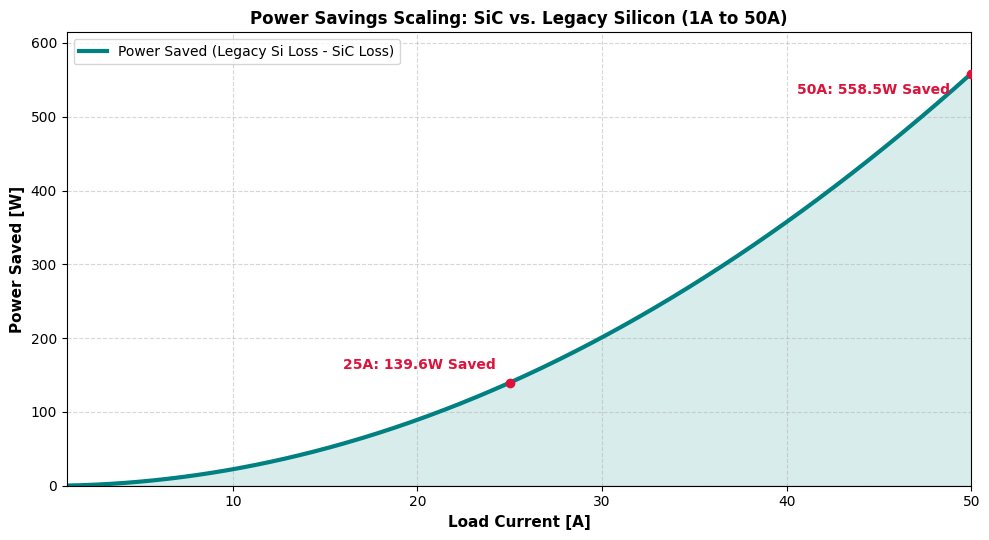

In [7]:
# ==============================================================================
# Power Savings Scaling from 1A to 50A
# ==============================================================================
I_sweep_savings = np.linspace(1.0, 50.0, 500)

# Compute individual losses (P = I^2 * R) across the range
P_loss_sic_sweep = (I_sweep_savings ** 2) * rds_sic
P_loss_si_sweep = (I_sweep_savings ** 2) * rds_si_legacy
power_savings_sweep = P_loss_si_sweep - P_loss_sic_sweep

# Create the plot
plt.figure(figsize=(10, 5.5))
plt.plot(I_sweep_savings, power_savings_sweep, color='teal', lw=3, label='Power Saved (Legacy Si Loss - SiC Loss)')
plt.fill_between(I_sweep_savings, power_savings_sweep, color='teal', alpha=0.15)

# Highlight key points (e.g., 25A and 50A)
savings_25a = (25.0 ** 2) * (rds_si_legacy - rds_sic)
savings_50a = (50.0 ** 2) * (rds_si_legacy - rds_sic)

plt.scatter([25.0, 50.0], [savings_25a, savings_50a], color='crimson', zorder=5)
plt.annotate(f'25A: {savings_25a:.1f}W Saved', (25.0, savings_25a), textcoords="offset points", xytext=(-10,10), ha='right', fontweight='bold', color='crimson')
plt.annotate(f'50A: {savings_50a:.1f}W Saved', (50.0, savings_50a), textcoords="offset points", xytext=(-15,-15), ha='right', fontweight='bold', color='crimson')

plt.title('Power Savings Scaling: SiC vs. Legacy Silicon (1A to 50A)', fontsize=12, fontweight='bold')
plt.xlabel('Load Current [A]', fontsize=11, fontweight='bold')
plt.ylabel('Power Saved [W]', fontsize=11, fontweight='bold')
plt.xlim(1, 50)
plt.ylim(0, max(power_savings_sweep) * 1.1)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


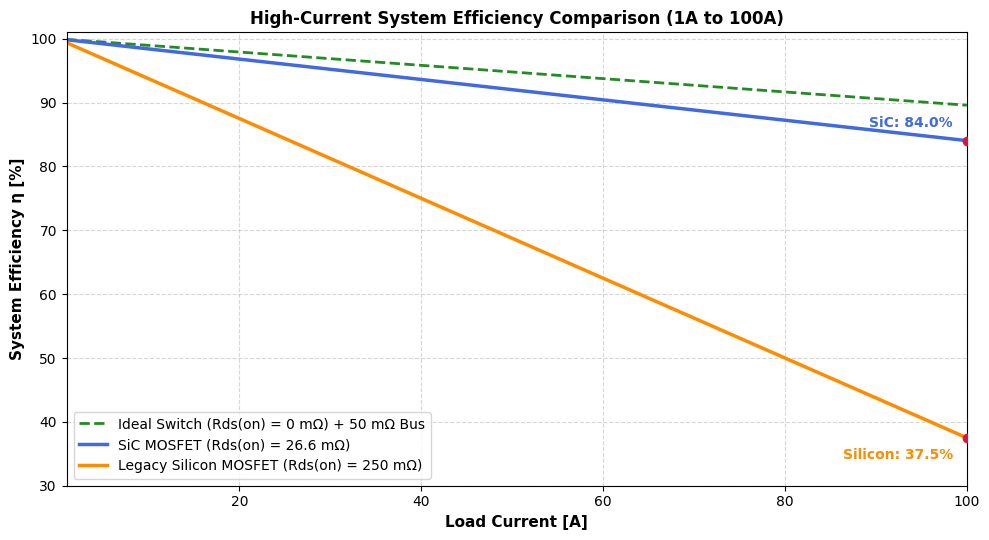

At 50A: SiC Efficiency =  92.0% | Legacy Silicon Efficiency =  68.8%
At 75A: SiC Efficiency =  88.0% | Legacy Silicon Efficiency =  53.1%
At 100A: SiC Efficiency =  84.0% | Legacy Silicon Efficiency =  37.5%


In [8]:
# ==============================================================================
# High-Current Efficiency Comparison up to 100A
# ==============================================================================
I_high_range = np.linspace(1.0, 100.0, 500)

# Calculate efficiencies up to 100A
eff_ideal_100a = compute_efficiency(I_high_range, rds_ideal)
eff_sic_100a = compute_efficiency(I_high_range, rds_sic)
eff_si_100a = compute_efficiency(I_high_range, rds_si_legacy)

# Create comparison plot
plt.figure(figsize=(10, 5.5))
plt.plot(I_high_range, eff_ideal_100a, label='Ideal Switch (Rds(on) = 0 mΩ) + 50 mΩ Bus', color='forestgreen', ls='--', lw=2)
plt.plot(I_high_range, eff_sic_100a, label='SiC MOSFET (Rds(on) = 26.6 mΩ)', color='royalblue', lw=2.5)
plt.plot(I_high_range, eff_si_100a, label='Legacy Silicon MOSFET (Rds(on) = 250 mΩ)', color='darkorange', lw=2.5)

# Highlight key values at 100A
eff_sic_at_100 = compute_efficiency(np.array([100.0]), rds_sic)[0]
eff_si_at_100 = compute_efficiency(np.array([100.0]), rds_si_legacy)[0]

plt.scatter([100.0, 100.0], [eff_sic_at_100, eff_si_at_100], color='crimson', zorder=5)
plt.annotate(f'SiC: {eff_sic_at_100:.1f}%', (100.0, eff_sic_at_100), textcoords="offset points", xytext=(-10,10), ha='right', fontweight='bold', color='royalblue')
plt.annotate(f'Silicon: {eff_si_at_100:.1f}%', (100.0, eff_si_at_100), textcoords="offset points", xytext=(-10,-15), ha='right', fontweight='bold', color='darkorange')

plt.title('High-Current System Efficiency Comparison (1A to 100A)', fontsize=12, fontweight='bold')
plt.xlabel('Load Current [A]', fontsize=11, fontweight='bold')
plt.ylabel('System Efficiency η [%]', fontsize=11, fontweight='bold')
plt.xlim(1, 100)
plt.ylim(30, 101)  # Set lower limit to catch the steep drop
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

# Print summary at specific high current thresholds
for amp in [50, 75, 100]:
    e_sic = compute_efficiency(np.array([float(amp)]), rds_sic)[0]
    e_si = compute_efficiency(np.array([float(amp)]), rds_si_legacy)[0]
    print(f"At {amp}A: SiC Efficiency = {e_sic:5.1f}% | Legacy Silicon Efficiency = {e_si:5.1f}%")


### 🚀 High-Current Efficiency Analysis (Up to $100\text{ A}$)

When scaling the load current up to extreme thresholds like **$100\text{ A}$**, the impact of the switch's internal on-resistance ($R_{\text{DS(on)}}$) changes from a minor parasitic issue to the primary factor dictating system viability:

* **At $50\text{ A}$:**
  * **SiC MOSFET:** Remains highly efficient at **$92.0\%$**.
  * **Legacy Silicon:** Drops down to **$68.8\%$**, dissipating substantial heat ($625\text{ W}$ in the switch alone!).
* **At $75\text{ A}$:**
  * **SiC MOSFET:** Maintains **$88.0\%$** efficiency.
  * **Legacy Silicon:** Plummets to **$53.1\%$** (nearly half of your input power is wasted as heat).
* **At $100\text{ A}$:**
  * **SiC MOSFET:** Still delivers a functional **$84.0\%$** efficiency.
  * **Legacy Silicon:** Plummets to a catastrophic **$37.5\%$** efficiency.

#### Why This Matters for Engineering
At $100\text{ A}$, a system utilizing the legacy silicon switch would dissipate **$2,500\text{ W}$** of power just as heat in the junction ($P = 100^2 \cdot 0.25$). This level of thermal output is equivalent to running multiple commercial space heaters inside your power enclosure, which would immediately destroy the silicon junction without massive, heavy liquid-cooling systems.

By contrast, the SiC device dissipates only **$265.9\text{ W}$** at $100\text{ A}$. While still requiring proper thermal management, this makes high-power applications like DC fast-charging and heavy EV traction inverters feasible and compact.

## 🏁 Episode 03: Concluding Final Remarks

In this episode, we have successfully analyzed and visualized the physical concept of **efficiency** and the profound impact of parasitic elements in electrical systems:

1. **Parasitic Elements Dominate:** Wiring, connection paths, and internal supply impedances are not negligible. At typical operating currents, they can easily account for the majority of the losses in a system with high-efficiency switches.
2. **The Wide-Bandgap (WBG) Paradigm:** Upgrading to Silicon Carbide (SiC) or Gallium Nitride (GaN) technologies dramatically lowers channel resistance, keeping system efficiencies high even under intensive operating currents.
3. **Quadratic Escalation:** Because conduction losses follow $P_{\text{loss}} = I^2 R$, any small increase in parasitic resistance or current demand triggers a quadratic explosion of heat. This makes WBG devices indispensable for compact, high-power designs where thermal management and heat-sinking capabilities are strictly constrained.

By matching the analytical equations in Python to the exact `.MEAS` directives from QSPICE, we have established a solid workflow to optimize and predict the thermal behavior of any power stage before stepping into the physical hardware laboratory.

---
